# 게임 설계 실습: 레드 드래곤 토벌 RPG

> **기획 미션:** 신입 게임 개발자인 당신에게 소형 RPG의 전투 시스템 개발이 맡겨졌습니다. 기획서를 읽고 **상속(IS-A)** 과 **구성(HAS-A)** 기반으로 클래스를 설계하세요.
>

## 📋 게임 기획서

**스토리**
전사 '아서'가 불타는 화염검 한 자루를 들고 던전에 들어갑니다. 슬라임과 골렘을 쓰러뜨리며 성장하고, 전리품을 모아 최종 보스 **레드 드래곤**에 도전합니다. 그런데 드래곤은 불 속성이라 화염검이 잘 통하지 않습니다. 아서는 어떻게 이길 수 있을까요?

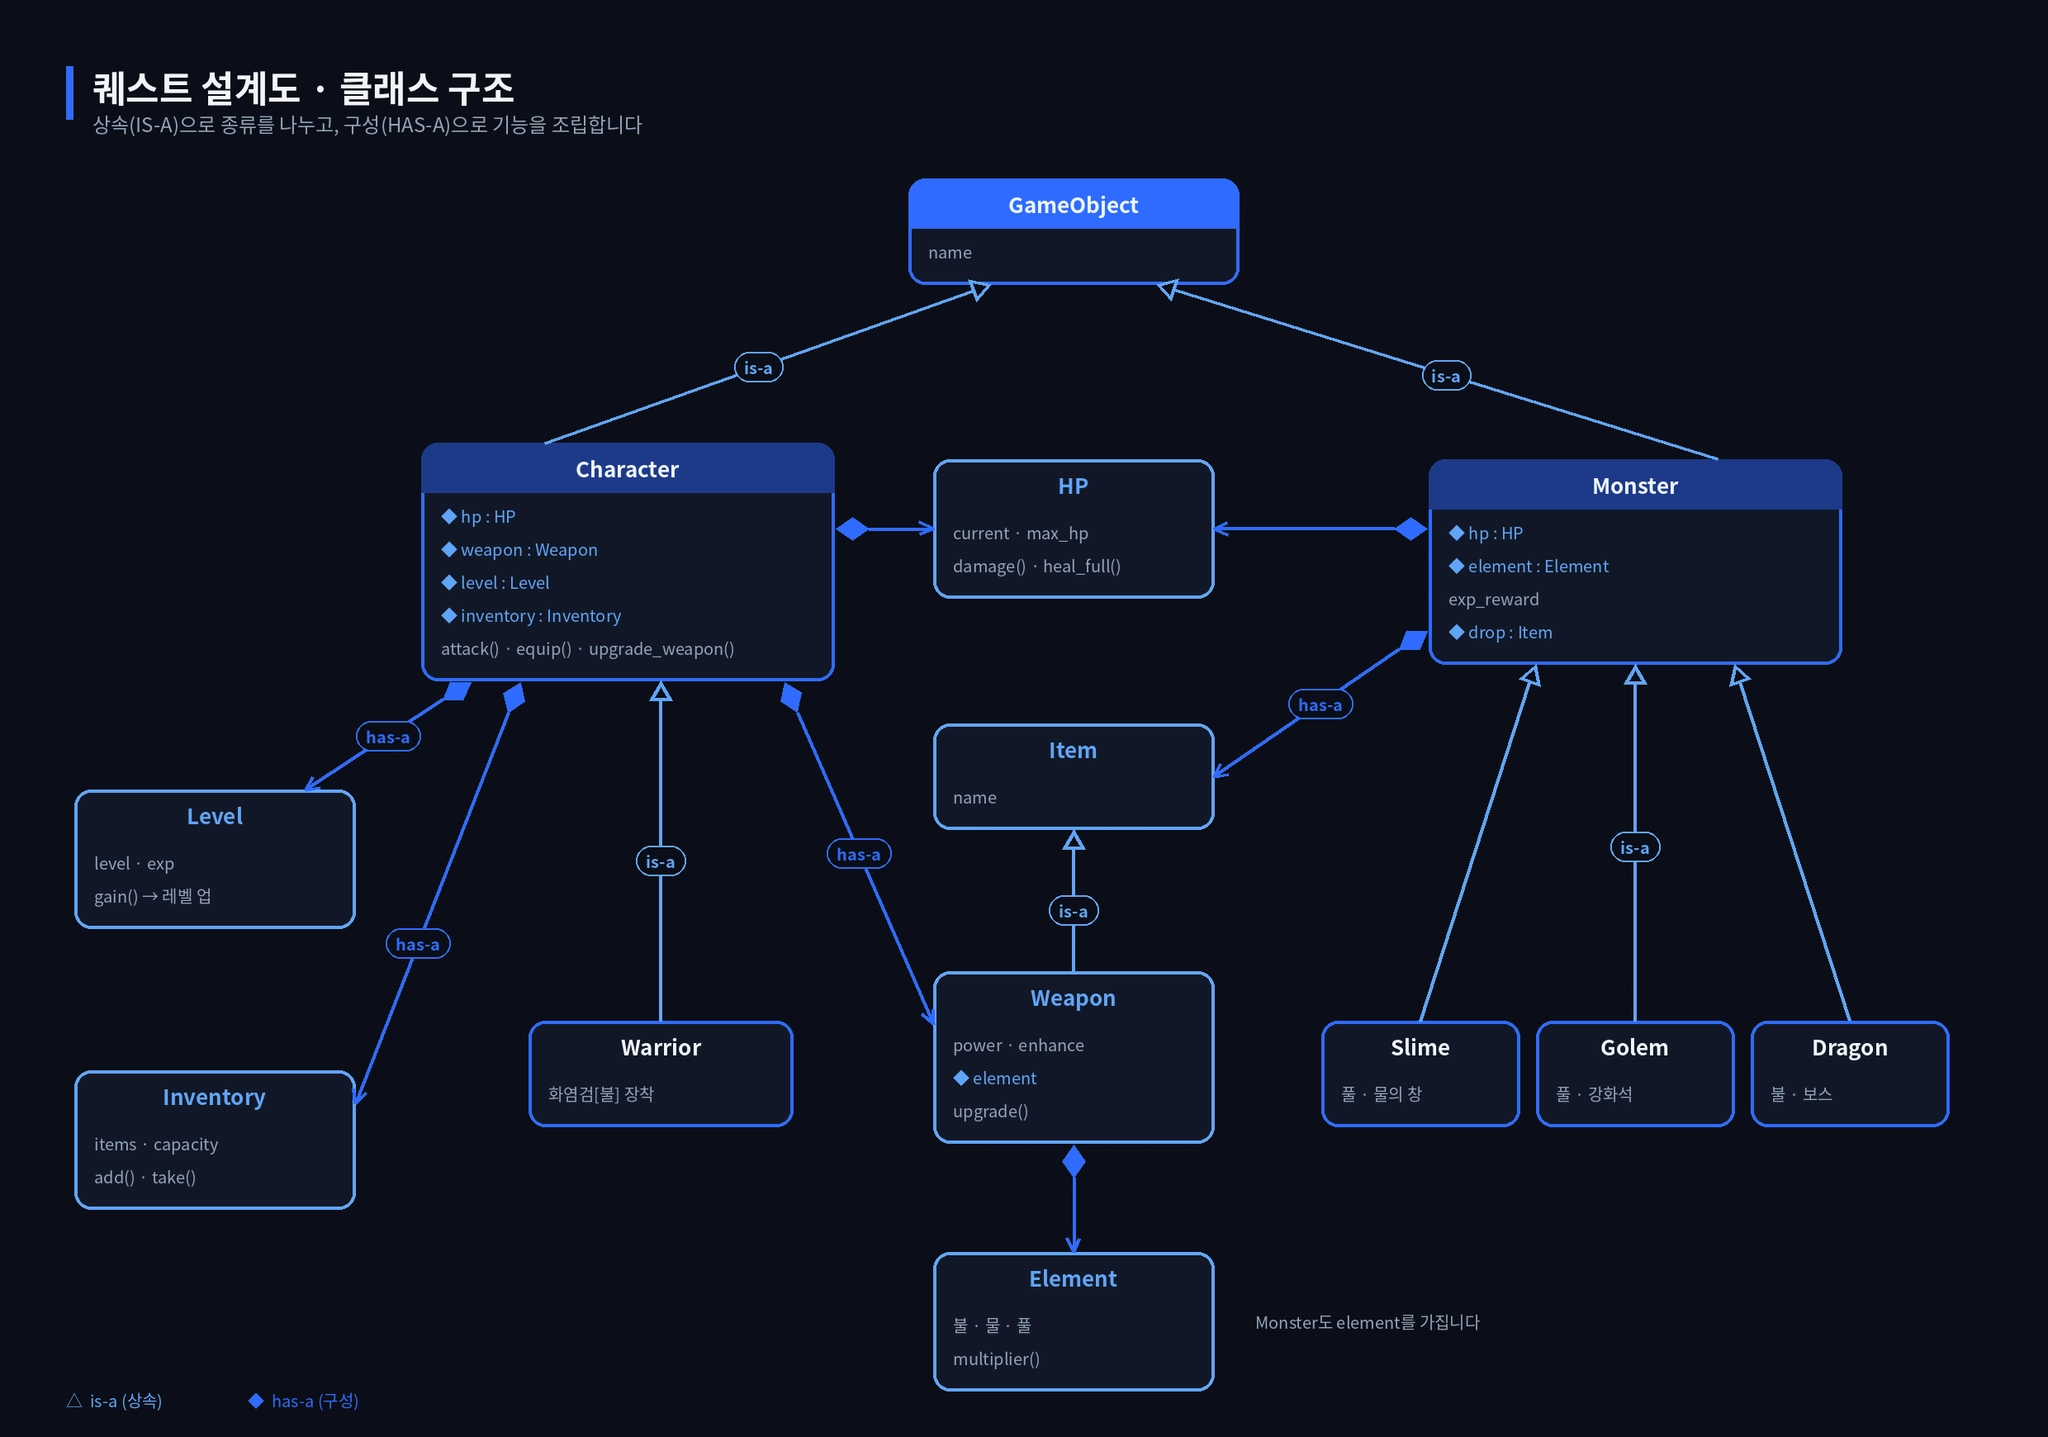

## 🗺️ 퀘스트 1. 세계의 기초 만들기 (상속)

다음 클래스를 작성하세요.

- `GameObject(name)` : 모든 게임 객체의 부모
- `HP(max_hp)` : `current`, `max_hp`, `damage(amount)` (0 아래로 내려가지 않음), `heal_full()`, `is_alive()`
- `Item(name)` : 모든 아이템의 부모
- `Monster(GameObject)` : `hp`(HP 객체), `element`, `exp_reward`, `drop`(없으면 `None`)
- `Slime`, `Golem`, `Dragon` 은 `Monster` 를 상속하고, 밸런스 표대로 `super().__init__()` 을 호출

> 💡 생각해 보기: 왜 `Monster` 가 `HP` 를 **상속**하지 않고 **속성으로 가지는** 걸까요?
>

In [55]:
# 모든 게임 객체 부모
class GameObject:
    def __init__(self, name, x=0, y=0):
        self.name=name
        self.x=x
        self.y=y

    def move(self, dx, dy):
        self.x += dx
        self.y += dy

    def info(self):
        return f"{self.name} ({self.x}, {self.y})"
    

# 체력 부품 (몬스터, 캐릭터 적용)
class HP:
    def __init__(self, max_hp):
        self.max_hp=max_hp
        self.current_hp=max_hp

    def damage(self, amount):
        if self.current_hp <= amount:
            self.current_hp=0
        else:
            self.current_hp -= amount

    def is_alive(self):
        return self.current_hp > 0

    def heal_full(self):
        self.current_hp = self.max_hp


# 모든 아이템의 부모
class Item:
    def __init__(self, name):
        self.name=name

In [56]:
# 모든 몬스터 클래스 모음
class Monster(GameObject):
    def __init__(self, name, max_hp, element, exp_reward, drop=None):
        super().__init__(name)
        self.hp = HP(max_hp)
        self.element = element
        self.exp_reward = exp_reward
        self.drop = drop
          


class Dragon(Monster):
    def __init__(self, name="레드 드래곤", max_hp=300, element=None, exp_reward=500, drop=None):
        if element is None:
            element = Element("불")
        super().__init__(name, max_hp, element, exp_reward, drop)


class Slime(Monster):
    def __init__(self, name="슬라임", max_hp=40, element=None,
                 exp_reward=60, drop=None):
        if element is None:
            element = Element("풀")
        if drop is None:
            drop = Weapon("물의 창", 25, Element("물"))  
        super().__init__(name, max_hp, element, exp_reward, drop)

        
class Golem(Monster):
    def __init__(self, name="골렘", max_hp=120, element=None,
                 exp_reward=90, drop=None):
        if element is None:
            element = Element("풀")
        if drop is None:
            drop = Item("강화석")
        super().__init__(name, max_hp, element, exp_reward, drop)

In [57]:
# 확인용 코드
d = Dragon(element="임시 불")
print(d)

## 🔥 퀘스트 2. 재미 요소 ① 속성 상성

📷 

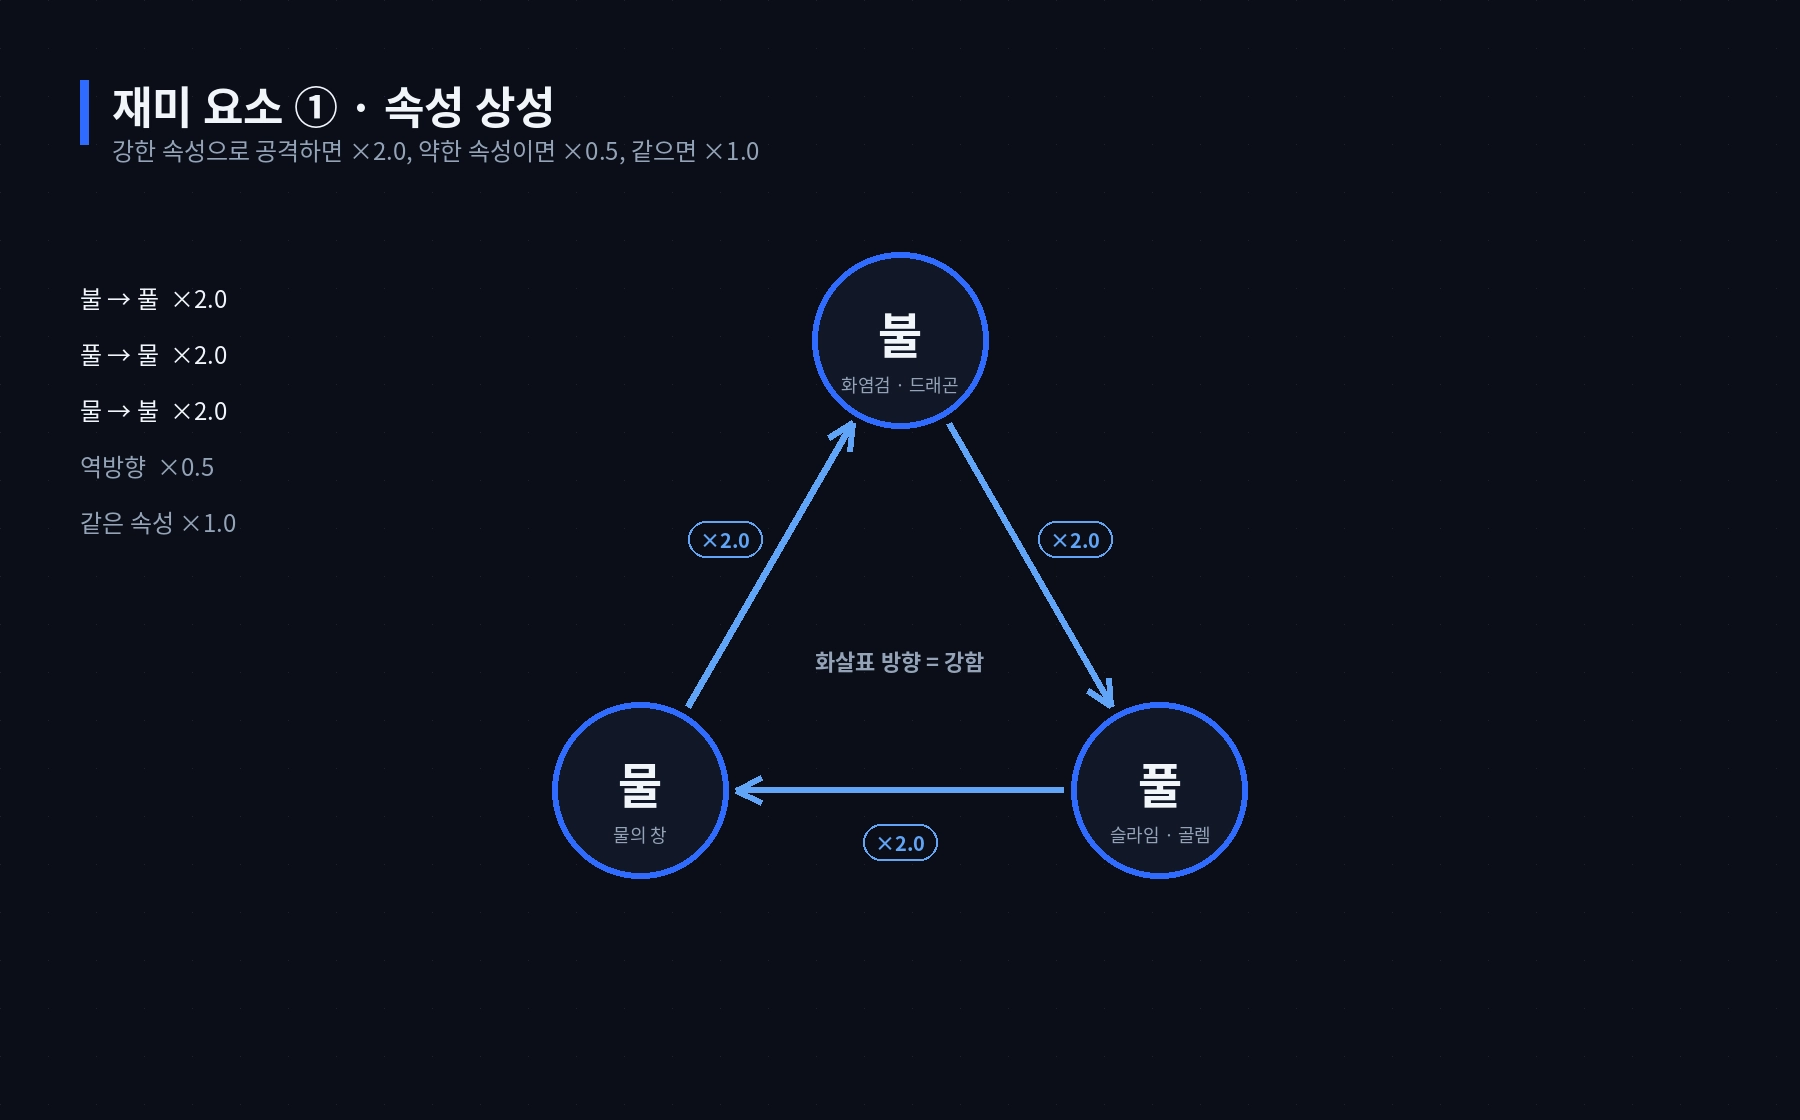

**규칙:** 불 → 풀 → 물 → 불 순서로 강합니다.

- 강한 속성으로 공격 : **×2.0**
- 약한 속성으로 공격 : **×0.5**
- 같은 속성 : **×1.0**

**구현 조건**

- `Element(name)` 클래스, `multiplier(target)` → 배율 반환
- `Weapon(Item)` : 무기는 아이템**이다** (IS-A)
    - `power`, `element` (Element 객체를 **갖는다**, HAS-A), `enhance`(강화 단계, 기본 0)
    - `upgrade()` → 강화 단계 +1, 공격력 +5
    - `__str__()` → `"+1 물의 창[물]"` 형식 (강화 0이면 `"화염검[불]"`)

In [58]:
class Element:
    STRONG = {"불": "풀", "풀": "물", "물":"불"}

    def __init__(self, name):
        self.name=name

    def multiplier(self, target):
        if Element.STRONG[self.name] == target.name: # 이길 때
            return 2.0
        if Element.STRONG[target.name] == self.name: # 질 때
            return 0.5
        return 1.0

### 퀘스트2. 확인 코드

In [59]:
# 상성 확인 코드
fire = Element("불")
print(fire.multiplier(Element("풀")), fire.multiplier(Element("물")), fire.multiplier(Element("불")))

2.0 0.5 1.0


In [60]:
class Weapon(Item):
    def __init__(self, name, power, element):
        super().__init__(name)
        self.power = power
        self.element = element       
        self.enhance = 0

    def upgrade(self):
        self.enhance += 1
        self.power += 5

    def __str__(self):
        tag = f"+{self.enhance} " if self.enhance else ""
        return f"{tag}{self.name}[{self.element.name}]"
    

In [61]:
# 그저 확인용
spear = Weapon("물 창", 100, Element("물"))
print(spear)
spear.upgrade()
print(spear, spear.power)

물 창[물]
+1 물 창[물] 105


## ⭐ 퀘스트 3. 재미 요소 ② 레벨 업

**규칙:** 다음 레벨까지 필요한 경험치 = `현재 레벨 × 100`. 한 번에 경험치를 많이 받으면 **여러 번 연속 레벨 업**이 가능해야 합니다.

- `Level` 클래스 : `level`(1부터), `exp`(0부터)
- `need()` → 필요 경험치
- `gain(amount)` → 경험치를 더하고, **오른 레벨 수**를 반환
- 캐릭터가 레벨 업하면 **최대 HP +20 (레벨당)**, 체력 완전 회복

In [62]:
# 레벨 업 로직
class Level:
    def __init__(self):
        self.level = 1
        self.exp = 0

    def need(self):
        return self.level * 100

    def gain(self, amount):
        self.exp += amount
        up = 0
        while self.exp >= self.need():
            self.exp -= self.need()
            self.level += 1
            up += 1
        return up

### 퀘스트3. 확인 코드

In [63]:
lv = Level()
print(lv.gain(150), lv.level, lv.exp)
print(lv.gain(500), lv.level, lv.exp)

1 2 50
2 4 50


## 🎒 퀘스트 4. 재미 요소 ③ 드롭 · 장비 교체 · 강화

- `Inventory(capacity)` : `items` 리스트
    - `add(item)` → 꽉 찼으면 `False`, 아니면 넣고 `True`
    - `take(name)` → 이름이 같은 아이템을 꺼내서 반환 (없으면 `None`)
- `Character(GameObject)` : `hp`, `weapon`, `level`, `inventory(5칸)` 을 **갖는다**
    - `attack(target)` → 전투 로그(문자열 리스트) 반환. 흐름은 아래 다이어그램 참고
    - `equip(name)` → 인벤토리의 무기로 교체, 쓰던 무기는 인벤토리로
    - `upgrade_weapon()` → 강화석 1개를 소모해 현재 무기 강화
- `Warrior(Character)` : 체력 150, 화염검[불] 30으로 시작

📷 

**전투 로그 형식**

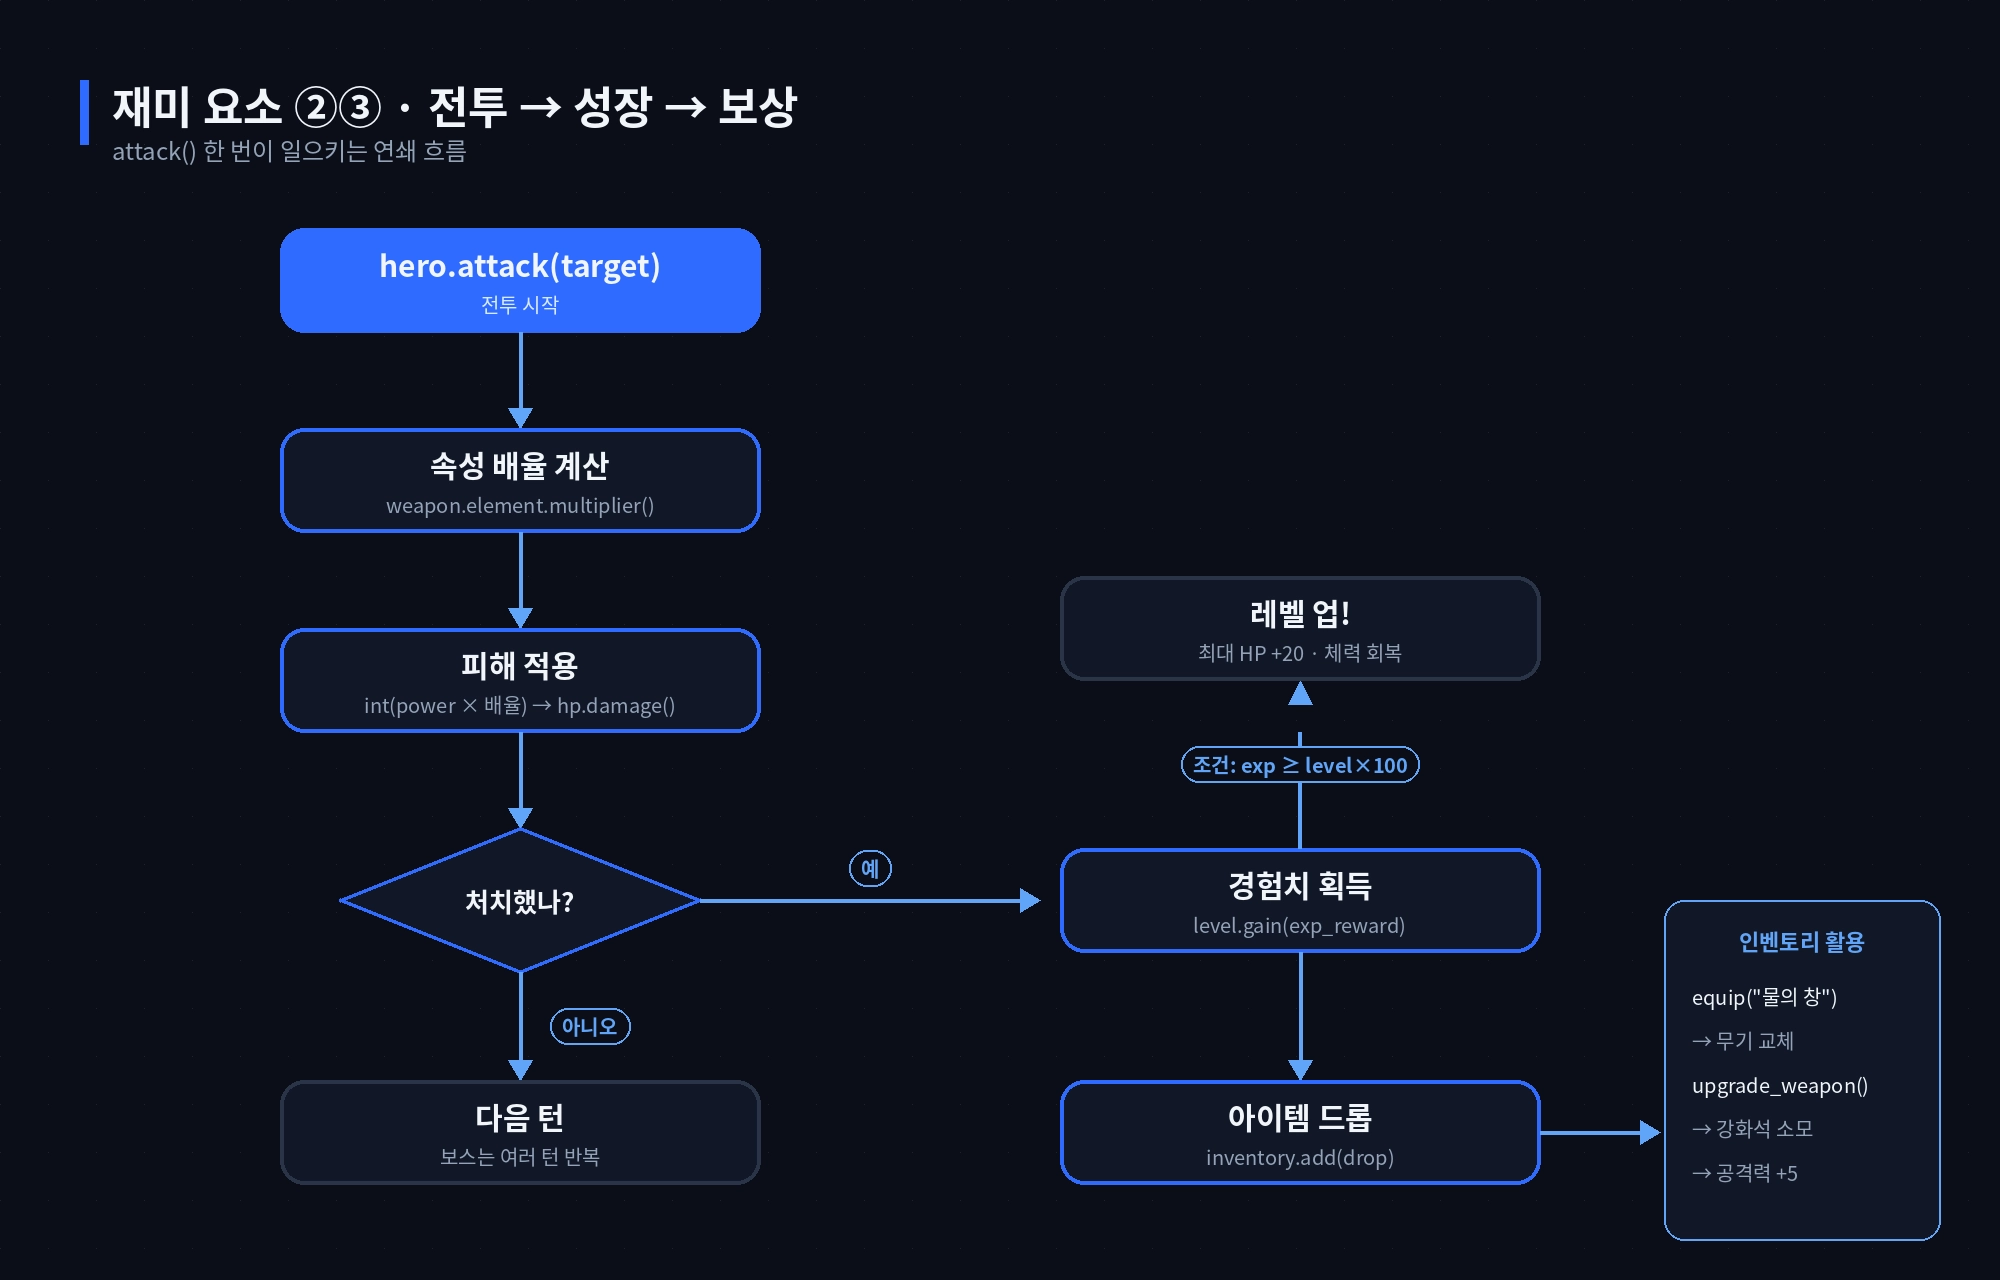

In [64]:
# 인벤토리와 아이템 넣었다가 뺐다가 함수
class Inventory:
    def __init__(self, capacity):
        self.capacity=capacity
        self.items=[]

    def add(self, item):
        if len(self.items) >= self.capacity:
            return False
        else:
            self.items.append(item)
        return True

    def take(self, name):
        for item in self.items:
            if item.name == name:
                self.items.remove(item)
                return item
        return None

In [65]:
# 그저 확인용
inv = Inventory(2)
print(inv.add(Item("a")), inv.add(Item("b")), inv.add(Item("c")))
print(inv.take("z"))
print([i.name for i in inv.items])
print(inv.items[1].name)

True True False
None
['a', 'b']
b


In [66]:
# 캐릭터와 직업들, 위에 만들어둔 레벨업 등 기능 연결시키기
class Character(GameObject):
    def __init__(self, name, max_hp, weapon):
        super().__init__(name)
        self.hp = HP(max_hp)              # HAS-A
        self.weapon = weapon              # HAS-A
        self.level = Level()              # HAS-A
        self.inventory = Inventory(5)     # HAS-A

    def attack(self, target):
        mult = self.weapon.element.multiplier(target.element)
        dmg = int(self.weapon.power * mult)
        target.hp.damage(dmg)
        log = [f"{self.name}의 {self.weapon} 공격! {target.name}에게 {dmg} 피해 (x{mult})"]

        if not target.hp.is_alive():
            log.append(f"{target.name} 처치! EXP +{target.exp_reward}")
            up = self.level.gain(target.exp_reward)
            if up:
                self.hp.max_hp += 20 * up
                self.hp.heal_full()
                log.append(f"레벨 업! Lv.{self.level.level} (최대 HP {self.hp.max_hp})")
            if target.drop and self.inventory.add(target.drop):
                log.append(f"'{target.drop.name}' 획득!")
        return log

    def equip(self, name):
        item = self.inventory.take(name)
        if item is None:
            return False
        if not isinstance(item, Weapon):
            self.inventory.add(item)      # 무기가 아니면 도로 넣기
            return False
        self.inventory.add(self.weapon)   # 쓰던 무기는 인벤토리로
        self.weapon = item
        return True

    def upgrade_weapon(self):
        stone = self.inventory.take("강화석")
        if stone is None:
            return False
        self.weapon.upgrade()
        return True

In [67]:
# 워리어 캐릭터 생성
class Warrior(Character):
    def __init__(self, name):
        super().__init__(name, 150, Weapon("화염검", 30, Element("불")))

### 퀘스트4. 확인 코드

In [68]:
hero = Warrior("아서")
for line in hero.attack(Slime()):
    print(line)

아서의 화염검[불] 공격! 슬라임에게 60 피해 (x2.0)
슬라임 처치! EXP +60
'물의 창' 획득!


In [69]:
hero = Warrior("아서")

# 1) 슬라임 사냥
for line in hero.attack(Slime()):
    print(line)
print([i.name for i in hero.inventory.items])
print("---")

# 2) 골렘 사냥 (쓰러질 때까지 공격)
golem = Golem()
while golem.hp.is_alive():
    for line in hero.attack(golem):
        print(line)
print("---")

# 3) 보스전 준비: 무기 교체 + 강화
print(hero.equip("물의 창"), hero.weapon, [i.name for i in hero.inventory.items])
print(hero.upgrade_weapon(), hero.weapon, hero.weapon.power)
print("---")

# 4) 보스전
boss = Dragon()
turn = 0
while boss.hp.is_alive():
    turn += 1
    hero.attack(boss)
print(f"{turn}턴 만에 보스 처치! Lv.{hero.level.level}, EXP {hero.level.exp}")

아서의 화염검[불] 공격! 슬라임에게 60 피해 (x2.0)
슬라임 처치! EXP +60
'물의 창' 획득!
['물의 창']
---
아서의 화염검[불] 공격! 골렘에게 60 피해 (x2.0)
아서의 화염검[불] 공격! 골렘에게 60 피해 (x2.0)
골렘 처치! EXP +90
레벨 업! Lv.2 (최대 HP 170)
'강화석' 획득!
---
True 물의 창[물] ['강화석', '화염검']
True +1 물의 창[물] 30
---
5턴 만에 보스 처치! Lv.4, EXP 50
